# XGBoost Implementation from Scratch

## Project Overview
This notebook implements XGBoost (Extreme Gradient Boosting) from scratch using the **exact greedy split-finding algorithm**. The implementation is benchmarked against the official XGBoost library on the BankChurners dataset for customer churn prediction.

## Pipeline Workflow

### 1. **Data Preparation**
- Load BankChurners.csv dataset
- Detect and handle target column (churn/attrition)
- Drop leakage columns and ID-like features
- One-hot encode categorical variables
- Split into train (56%), validation (14%), and test (30%) sets

### 2. **Algorithm Implementation**
- **Exact Greedy Split Finder**: Scans all possible split points for each feature
- **Sparsity-Aware Handling**: Manages missing values by testing both left and right default directions
- **XGBoost Tree**: Single regression tree with gain-based splitting and post-pruning
- **Gradient Boosting**: Logistic loss with row/column subsampling and early stopping

### 3. **Model Training**
- Train with scale_pos_weight to handle class imbalance (84% non-churn, 16% churn)
- Use early stopping on validation set to prevent overfitting
- Apply row subsampling (80%) and column subsampling (80%)
- Regularization: L1 (reg_alpha), L2 (reg_lambda), and gamma for complexity control

### 4. **Evaluation & Diagnostics**
- Compare scratch implementation vs official XGBoost
- Analyze exact vs histogram tree methods
- Evaluate post-pruning effects on model complexity
- Generate ROC curves, feature importance plots, and tree visualizations

### 5. **Key Metrics**
- **AUC (Area Under ROC Curve)**: Overall model discrimination ability
- **F1 Score**: Harmonic mean of precision and recall
- **Precision**: Accuracy of positive predictions
- **Recall**: Coverage of actual positive cases

---


## Import Libraries and Setup

In [ ]:
from __future__ import annotations

import os
import time
from typing import Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve,
    precision_recall_curve, average_precision_score,
)

try:
    import xgboost as xgb
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False

np.random.seed(0)


## Configuration and Hyperparameters

In [ ]:
DATA_PATH = "/content/BankChurners.csv"
OUTPUT_DIR = "/content/outputs" if os.path.isdir("/content") else os.path.join(os.getcwd(), "outputs")
os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f"Figures will be saved to: {OUTPUT_DIR}")

CANDIDATE_TARGET_NAMES = [
    "Attrition_Flag", "Churn Value", "Churn Label",
    "churn", "Churn", "CHURN", "Churn?", "Exited", "exited",
    "is_churn", "IsChurn", "Churned",
]
LEAKAGE_COLUMN_NAMES = ["Churn Label", "Churn Value", "Churn Score", "Churn Reason"]
POSITIVE_LABEL_STRINGS = {"yes", "true", "1", "churn", "exited", "attrited customer"}

ES_ROUNDS = 20
EVAL_METRIC = "logloss"

BASE_PARAMS = dict(
    max_depth=5, reg_alpha=1.0, learning_rate=0.1, n_estimators=300,
    reg_lambda=1.0, gamma=1.0, min_child_weight=0.0,
    subsample=0.8, colsample_bytree=0.8, post_prune=True,
)
CV_BASE_PARAMS = dict(
    max_depth=6, reg_alpha=1.0, learning_rate=0.1, n_estimators=150,
    subsample=0.8, colsample_bytree=0.8, post_prune=True,
)


Figures will be saved to: /content/outputs


## Load and Clean Data

In [ ]:
df = pd.read_csv(DATA_PATH)
print(f"Loaded {DATA_PATH}, shape={df.shape}")

target_col = next((c for c in CANDIDATE_TARGET_NAMES if c in df.columns), df.columns[-1])
print(f"Using '{target_col}' as the target column")

leak_cols = [c for c in LEAKAGE_COLUMN_NAMES if c != target_col and c in df.columns]
leak_cols += [c for c in df.columns if c.startswith("Naive_Bayes_Classifier")]
if leak_cols:
    print(f"Dropping target-leakage columns: {leak_cols}")
    df = df.drop(columns=leak_cols)

for c in df.columns:
    if c != target_col and not pd.api.types.is_numeric_dtype(df[c]):
        coerced = pd.to_numeric(df[c], errors="coerce")
        if coerced.notna().mean() > 0.95:
            df[c] = coerced

id_cols = [c for c in df.columns if c != target_col and not pd.api.types.is_numeric_dtype(df[c])
           and df[c].nunique() / len(df) > 0.9]
if id_cols:
    print(f"Dropping ID-like columns: {id_cols}")
    df = df.drop(columns=id_cols)

df = df.dropna(subset=[target_col]).reset_index(drop=True)
print(f"Shape after cleaning: {df.shape}")

Loaded /content/BankChurners.csv, shape=(10127, 23)
Using 'Attrition_Flag' as the target column
Dropping target-leakage columns: ['Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1', 'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2']
Shape after cleaning: (10127, 21)


## Target Variable and Feature Engineering

In [ ]:
y_raw = df[target_col]
if not pd.api.types.is_numeric_dtype(y_raw):
    y = y_raw.astype(str).str.strip().str.rstrip(".").str.lower().isin(POSITIVE_LABEL_STRINGS).astype(float).values
else:
    uniques = sorted(y_raw.dropna().unique())
    y = (y_raw == uniques[-1]).astype(float).values if len(uniques) == 2 else y_raw.astype(float).values

n_pos, n_neg = int(np.nansum(y)), int(len(y) - np.nansum(y))
print(f"Target distribution: {n_neg} negative / {n_pos} positive ({n_pos / len(y):.1%} churn rate)")

X_df = pd.get_dummies(df[[c for c in df.columns if c != target_col]], drop_first=True, dummy_na=True)
X_A, feat_names = X_df.values.astype(float), list(X_df.columns)
print(f"Total features: {X_A.shape[1]}")

Target distribution: 8500 negative / 1627 positive (16.1% churn rate)
Total features: 38


## Train/Validation/Test Split

In [ ]:
idx = np.arange(len(df))
idx_train_full, idx_test = train_test_split(idx, test_size=0.3, random_state=0, stratify=y)
idx_train, idx_val = train_test_split(idx_train_full, test_size=0.2, random_state=0, stratify=y[idx_train_full])
print(f"Train: {len(idx_train)}  Val: {len(idx_val)}  Test: {len(idx_test)}")

y_train, y_val, y_test = y[idx_train], y[idx_val], y[idx_test]
X_train, X_val, X_test = X_A[idx_train], X_A[idx_val], X_A[idx_test]

n_pos_train, n_neg_train = int(np.sum(y_train == 1)), int(np.sum(y_train == 0))
spw_value = n_neg_train / n_pos_train if n_pos_train > 0 else 1.0
print(f"Computed scale_pos_weight from training fold: {n_neg_train}/{n_pos_train} = {spw_value:.4f}")

CONFIGS = [("with_spw", spw_value)]


Train: 5670  Val: 1418  Test: 3039
Computed scale_pos_weight from training fold: 4759/911 = 5.2239


## Exact Greedy Split Finder Class

In [ ]:
class ExactGreedySplitFinder:
    """Exact greedy split finding (XGBoost's 'exact' tree method): for
    each feature, sort by value and scan every unique value as a
    candidate threshold, accumulating G/H left-to-right. Missing values
    are handled the sparsity-aware way — both "send missing left" and
    "send missing right" are evaluated and whichever gives higher gain
    is kept as the node's default direction."""

    def __init__(self, reg_lambda=1.0, reg_alpha=0.0, gamma=0.0, min_child_weight=1.0):
        self.reg_lambda, self.reg_alpha = reg_lambda, reg_alpha
        self.gamma, self.min_child_weight = gamma, min_child_weight

    def _similarity(self, g_sum, h_sum):
        num = np.where(g_sum > self.reg_alpha, g_sum - self.reg_alpha,
                        np.where(g_sum < -self.reg_alpha, g_sum + self.reg_alpha, 0.0))
        return (num ** 2) / (h_sum + self.reg_lambda)

    def leaf_weight(self, g_sum, h_sum):
        if g_sum > self.reg_alpha:
            num = g_sum - self.reg_alpha
        elif g_sum < -self.reg_alpha:
            num = g_sum + self.reg_alpha
        else:
            return 0.0
        return -num / (h_sum + self.reg_lambda)

    def best_split_for_feature(self, x_col, g, h, rows=None):
        rows = rows if rows is not None else np.arange(len(x_col))
        vals = x_col[rows]
        missing_mask = np.isnan(vals)
        valid_rows, missing_rows = rows[~missing_mask], rows[missing_mask]
        if valid_rows.size < 2:
            return None

        order = np.argsort(x_col[valid_rows])
        sorted_rows = valid_rows[order]
        v_sorted = x_col[sorted_rows]
        g_sorted, h_sorted = g[sorted_rows], h[sorted_rows]

        G_miss, H_miss = g[missing_rows].sum(), h[missing_rows].sum()
        G_cum, H_cum = np.cumsum(g_sorted), np.cumsum(h_sorted)
        G_total, H_total = G_cum[-1] + G_miss, H_cum[-1] + H_miss
        parent_sim = self._similarity(G_total, H_total)

        not_tie = v_sorted[1:] != v_sorted[:-1]
        if not_tie.size == 0:
            return None

        GL_a, HL_a = G_cum[:-1] + G_miss, H_cum[:-1] + H_miss
        GR_a, HR_a = G_total - GL_a, H_total - HL_a
        gain_a = 0.5 * (self._similarity(GL_a, HL_a) + self._similarity(GR_a, HR_a) - parent_sim) - self.gamma
        valid_a = not_tie & (HL_a >= self.min_child_weight) & (HR_a >= self.min_child_weight)
        gain_a = np.where(valid_a, gain_a, -np.inf)

        GL_b, HL_b = G_cum[:-1], H_cum[:-1]
        GR_b, HR_b = G_total - GL_b, H_total - HL_b
        gain_b = 0.5 * (self._similarity(GL_b, HL_b) + self._similarity(GR_b, HR_b) - parent_sim) - self.gamma
        valid_b = not_tie & (HL_b >= self.min_child_weight) & (HR_b >= self.min_child_weight)
        gain_b = np.where(valid_b, gain_b, -np.inf)

        best_a_i, best_b_i = int(np.argmax(gain_a)), int(np.argmax(gain_b))
        best_a, best_b = gain_a[best_a_i], gain_b[best_b_i]
        if best_a == -np.inf and best_b == -np.inf:
            return None

        i, default_left, gain = (best_a_i, True, best_a) if best_a >= best_b else (best_b_i, False, best_b)
        threshold = (v_sorted[i] + v_sorted[i + 1]) / 2.0
        return {"threshold": float(threshold), "gain": float(gain), "default_left": default_left}

    def best_split_all_features(self, X, g, h, feat_idx=None, rows=None):
        feat_idx = feat_idx if feat_idx is not None else range(X.shape[1])
        best = None
        for j in feat_idx:
            result = self.best_split_for_feature(X[:, j], g, h, rows)
            if result is not None and (best is None or result["gain"] > best["gain"]):
                best = {**result, "feature": j}
        return best


## Exact Greedy Tree Class

In [ ]:
class _Node:
    """`feature` is a global column index into X; `threshold` is a real
    feature value — no binning, so no bin-edge lookups needed anywhere."""
    __slots__ = ("feature", "threshold", "default_left", "left", "right",
                 "weight", "is_leaf", "gain", "g_sum", "h_sum")

    def __init__(self):
        self.feature = self.threshold = None
        self.default_left = True
        self.left = self.right = None
        self.weight, self.gain, self.g_sum, self.h_sum = 0.0, -np.inf, 0.0, 0.0
        self.is_leaf = True


class ExactGreedyTree:
    """One regression tree fit via exact-greedy split-finding, using
    XGBoost's gain/leaf-weight formulas."""

    def __init__(self, max_depth=6, min_child_weight=0.0, reg_lambda=1.0,
                 reg_alpha=0.0, gamma=0.0, post_prune=True, **_ignored):
        self.max_depth, self.post_prune = max_depth, post_prune
        self.finder = ExactGreedySplitFinder(reg_lambda, reg_alpha, gamma, min_child_weight)
        self.root = None
        self.feature_importance_ = self.feature_importance_gain_ = None
        self.feat_idx = None

    def _build(self, rows, X, g, h, depth):
        node = _Node()
        node.g_sum, node.h_sum = float(g[rows].sum()), float(h[rows].sum())

        if depth >= self.max_depth or len(rows) < 2:
            node.weight = self.finder.leaf_weight(node.g_sum, node.h_sum)
            return node

        best = self.finder.best_split_all_features(X, g, h, feat_idx=self.feat_idx, rows=rows)
        if best is None or (not self.post_prune and best["gain"] <= 0):
            node.weight = self.finder.leaf_weight(node.g_sum, node.h_sum)
            return node

        feature, threshold, default_left = best["feature"], best["threshold"], best["default_left"]
        values = X[rows, feature]
        missing = np.isnan(values)
        go_left = (values <= threshold) & ~missing
        if default_left:
            go_left |= missing

        left_rows, right_rows = rows[go_left], rows[~go_left]
        if len(left_rows) == 0 or len(right_rows) == 0:
            node.weight = self.finder.leaf_weight(node.g_sum, node.h_sum)
            return node

        node.is_leaf = False
        node.feature, node.threshold, node.default_left, node.gain = feature, threshold, default_left, best["gain"]
        self.feature_importance_[feature] += 1
        self.feature_importance_gain_[feature] += best["gain"]
        node.left = self._build(left_rows, X, g, h, depth + 1)
        node.right = self._build(right_rows, X, g, h, depth + 1)
        return node

    def _prune(self, node):
        """Post-order removal of splits with gain <= 0 once both children
        are leaves (mirrors XGBoost's post-pruning)."""
        if node.is_leaf:
            return
        self._prune(node.left)
        self._prune(node.right)
        if node.left.is_leaf and node.right.is_leaf and node.gain <= 0:
            node.is_leaf = True
            node.weight = self.finder.leaf_weight(node.g_sum, node.h_sum)
            self.feature_importance_[node.feature] -= 1
            self.feature_importance_gain_[node.feature] -= node.gain
            node.left = node.right = None

    def fit(self, X, g, h, sample_rows=None, feat_idx=None):
        self.feat_idx = feat_idx
        n_features = X.shape[1]
        self.feature_importance_ = np.zeros(n_features)
        self.feature_importance_gain_ = np.zeros(n_features)
        rows = sample_rows if sample_rows is not None else np.arange(X.shape[0])
        self.root = self._build(rows, X, g, h, depth=0)
        if self.post_prune and self.root is not None:
            self._prune(self.root)
        return self

    def predict(self, X):
        weights = np.empty(X.shape[0])
        self._apply(self.root, np.arange(X.shape[0]), X, weights)
        return weights

    def _apply(self, node, rows, X, weights):
        if node.is_leaf:
            weights[rows] = node.weight
            return
        col = X[rows, node.feature]
        missing = np.isnan(col)
        go_left = (col <= node.threshold) & ~missing
        if node.default_left:
            go_left |= missing
        self._apply(node.left, rows[go_left], X, weights)
        self._apply(node.right, rows[~go_left], X, weights)


## XGBoost From Scratch Implementation

In [ ]:
class XGBoostFromScratchExact:
    """Logistic-loss gradient boosting on top of ExactGreedyTree, with
    row/column subsampling, scale_pos_weight, and early stopping."""

    def __init__(self, n_estimators=100, learning_rate=0.3, max_depth=6, reg_lambda=1.0,
                 reg_alpha=0.0, gamma=1.0, min_child_weight=0.0, random_state=0,
                 subsample=1.0, colsample_bytree=1.0, post_prune=True,
                 scale_pos_weight=1.0, early_stopping_rounds=None, eval_metric="logloss", **_ignored):
        self.n_estimators, self.learning_rate, self.max_depth = n_estimators, learning_rate, max_depth
        self.reg_lambda, self.reg_alpha, self.gamma = reg_lambda, reg_alpha, gamma
        self.min_child_weight, self.random_state = min_child_weight, random_state
        self.subsample, self.colsample_bytree, self.post_prune = subsample, colsample_bytree, post_prune
        self.scale_pos_weight, self.early_stopping_rounds, self.eval_metric = (
            scale_pos_weight, early_stopping_rounds, eval_metric)
        self.trees, self.base_score_ = [], 0.0
        self.importance_ = self.importance_gain_ = None
        self.best_iteration_ = self.n_estimators_used_ = None

    @staticmethod
    def _sigmoid(z):
        return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

    @staticmethod
    def _logloss(y_true, p):
        eps = 1e-15
        p = np.clip(p, eps, 1 - eps)
        return -np.mean(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

    def _recompute_importance(self, n_features):
        """Rebuild importance arrays from self.trees after trimming back
        to the early-stopped iteration."""
        self.importance_ = np.zeros(n_features)
        self.importance_gain_ = np.zeros(n_features)
        for t in self.trees:
            self.importance_ += t.feature_importance_
            self.importance_gain_ += t.feature_importance_gain_

    def fit(self, X, y, eval_set=None, early_stopping_rounds=None):
        n_samples, n_features = X.shape
        p0 = np.clip(np.nanmean(y), 1e-6, 1 - 1e-6)
        self.base_score_ = np.log(p0 / (1 - p0))
        raw_pred = np.full(n_samples, self.base_score_)

        self.trees = []
        self.importance_ = np.zeros(n_features)
        self.importance_gain_ = np.zeros(n_features)
        rng = np.random.RandomState(self.random_state)

        n_sample_rows = max(2, int(round(n_samples * self.subsample)))
        n_sample_cols = max(1, int(round(n_features * self.colsample_bytree)))
        do_row_sub, do_col_sub = self.subsample < 1.0, self.colsample_bytree < 1.0
        sample_weight = np.where(y == 1, self.scale_pos_weight, 1.0)

        es_rounds = early_stopping_rounds if early_stopping_rounds is not None else self.early_stopping_rounds
        do_early_stop = eval_set is not None and es_rounds is not None
        if do_early_stop:
            X_val, y_val = eval_set
            raw_pred_val = np.full(X_val.shape[0], self.base_score_)
            best_score, best_iter, rounds_since_best = -np.inf, -1, 0

        self.best_iteration_ = None
        self.n_estimators_used_ = self.n_estimators
        self.first_round_grad_ = self.first_round_hess_ = None

        for m in range(self.n_estimators):
            p = self._sigmoid(raw_pred)
            grad, hess = (p - y) * sample_weight, p * (1 - p) * sample_weight
            if m == 0:
                self.first_round_grad_, self.first_round_hess_ = grad.copy(), hess.copy()

            sample_rows = rng.choice(n_samples, size=n_sample_rows, replace=False) if do_row_sub else None
            feat_idx = np.sort(rng.choice(n_features, size=n_sample_cols, replace=False)) if do_col_sub else None

            tree = ExactGreedyTree(max_depth=self.max_depth, min_child_weight=self.min_child_weight,
                                    reg_lambda=self.reg_lambda, reg_alpha=self.reg_alpha,
                                    gamma=self.gamma, post_prune=self.post_prune)
            tree.fit(X, grad, hess, sample_rows=sample_rows, feat_idx=feat_idx)
            self.trees.append(tree)
            self.importance_ += tree.feature_importance_
            self.importance_gain_ += tree.feature_importance_gain_
            raw_pred += self.learning_rate * tree.predict(X)

            if do_early_stop:
                raw_pred_val += self.learning_rate * tree.predict(X_val)
                p_val = self._sigmoid(raw_pred_val)
                score = auc_score(y_val, p_val) if self.eval_metric == "auc" else -self._logloss(y_val, p_val)
                if score > best_score + 1e-9:
                    best_score, best_iter, rounds_since_best = score, m, 0
                else:
                    rounds_since_best += 1
                if rounds_since_best >= es_rounds:
                    self.trees = self.trees[:best_iter + 1]
                    self.best_iteration_, self.n_estimators_used_ = best_iter, best_iter + 1
                    reported = -best_score if self.eval_metric != "auc" else best_score
                    print(f"  [early stopping] round {m + 1}: no improvement in {es_rounds} rounds — "
                          f"reverting to best iteration {best_iter + 1}/{self.n_estimators} "
                          f"({self.eval_metric}={reported:.4f})")
                    self._recompute_importance(n_features)
                    break
        return self

    def predict_raw(self, X):
        raw_pred = np.full(X.shape[0], self.base_score_)
        for tree in self.trees:
            raw_pred += self.learning_rate * tree.predict(X)
        return raw_pred

    def predict_proba(self, X):
        return self._sigmoid(self.predict_raw(X))

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)


## Evaluation Functions

In [ ]:
def auc_score(y_true, y_score):
    return roc_auc_score(y_true, y_score) if len(np.unique(y_true)) >= 2 else float("nan")


def best_threshold(y_true, y_prob, metric="f1", grid=None):
    grid = grid if grid is not None else np.linspace(0.05, 0.95, 181)
    best_t, best_score, best_metrics = 0.5, -1.0, None
    for t in grid:
        pred = (y_prob >= t).astype(int)
        precision, recall = precision_score(y_true, pred, zero_division=0), recall_score(y_true, pred, zero_division=0)
        f1 = f1_score(y_true, pred, zero_division=0)
        score = f1 if metric == "f1" else recall
        if score > best_score:
            best_t, best_score, best_metrics = t, score, {"precision": precision, "recall": recall, "f1": f1}
    return best_t, best_score, best_metrics


def print_classification_report(name, y_true, y_pred, y_prob):
    acc, auc = accuracy_score(y_true, y_pred), auc_score(y_true, y_prob)
    precision, recall = precision_score(y_true, y_pred, zero_division=0), recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    print(f"\n--- {name} ---")
    print(f"  Accuracy : {acc:.4f}   AUC: {auc:.4f}")
    print(f"  Precision: {precision:.4f}   Recall: {recall:.4f}   F1: {f1:.4f}")
    print(f"  Confusion matrix — TP:{tp}  FP:{fp}  TN:{tn}  FN:{fn}")
    return {"accuracy": acc, "auc": auc, "precision": precision, "recall": recall, "f1": f1}


def _count_leaves(node):
    return 1 if node.is_leaf else _count_leaves(node.left) + _count_leaves(node.right)



## Model Training and Evaluation

In [ ]:
models, metrics = {}, {}
for tag, spw in CONFIGS:
    print(f"CONFIG: {tag} — scale_pos_weight={spw:.2f}")

    params = {**BASE_PARAMS, "scale_pos_weight": spw}
    t0 = time.time()
    model = XGBoostFromScratchExact(**params)
    model.fit(X_train, y_train, eval_set=(X_val, y_val), early_stopping_rounds=ES_ROUNDS)
    fit_time = time.time() - t0
    stop_msg = (f" (early stopped at best iteration {model.best_iteration_ + 1})"
                if model.best_iteration_ is not None else " (ran full budget, no early stop)")
    print(f"[{tag}] trees used: {model.n_estimators_used_}/{BASE_PARAMS['n_estimators']}{stop_msg}")

    val_prob = model.predict_proba(X_val)
    t_opt, _, _ = best_threshold(y_val, val_prob, metric="f1")
    test_prob = model.predict_proba(X_test)
    test_pred_tuned = (test_prob >= t_opt).astype(int)
    test_pred_fixed = (test_prob >= 0.5).astype(int)

    m = print_classification_report(
        f"{tag}: scale_pos_weight={spw:.2f} ({X_train.shape[1]} features, fit={fit_time:.1f}s, "
        f"trees={model.n_estimators_used_}, threshold={t_opt:.2f} [tuned])",
        y_test, test_pred_tuned, test_prob,
    )
    m_fixed = print_classification_report(
        f"{tag}: scale_pos_weight={spw:.2f} — threshold=0.50 [fixed, isolates spw's effect]",
        y_test, test_pred_fixed, test_prob,
    )
    m.update(threshold=t_opt, n_features=X_train.shape[1], n_trees_used=model.n_estimators_used_,
             scale_pos_weight=spw, fit_time=fit_time, test_prob=test_prob,
             fixed_precision=m_fixed["precision"], fixed_recall=m_fixed["recall"], fixed_f1=m_fixed["f1"])
    models[tag], metrics[tag] = model, m


CONFIG: with_spw — scale_pos_weight=5.22
  [early stopping] round 178: no improvement in 20 rounds — reverting to best iteration 158/300 (logloss=0.0867)
[with_spw] trees used: 158/300 (early stopped at best iteration 158)

--- with_spw: scale_pos_weight=5.22 (38 features, fit=33.7s, trees=158, threshold=0.61 [tuned]) ---
  Accuracy : 0.9717   AUC: 0.9926
  Precision: 0.9241   Recall: 0.8975   F1: 0.9106
  Confusion matrix — TP:438  FP:36  TN:2515  FN:50

--- with_spw: scale_pos_weight=5.22 — threshold=0.50 [fixed, isolates spw's effect] ---
  Accuracy : 0.9694   AUC: 0.9926
  Precision: 0.8942   Recall: 0.9180   F1: 0.9060
  Confusion matrix — TP:448  FP:53  TN:2498  FN:40


## Diagnostic Analysis and Visualizations

SPLIT-FINDING DIAGNOSTIC: exact greedy best root split (round-0 gradients)
Best split overall: feature='Total_Trans_Ct' threshold=57.5000  gain=2765.7813  default_direction=left
TREE-METHOD DIAGNOSTIC: xgboost tree_method='exact' vs. 'hist'
tree_method      fit time (s)       AUC        F1
exact                    1.63    0.9924    0.9020
hist                     0.30    0.9925    0.9055
'hist' is 5.4x the speed of 'exact' here; at this data size the accuracy difference is expected to be small since exact greedy has no quantization error.


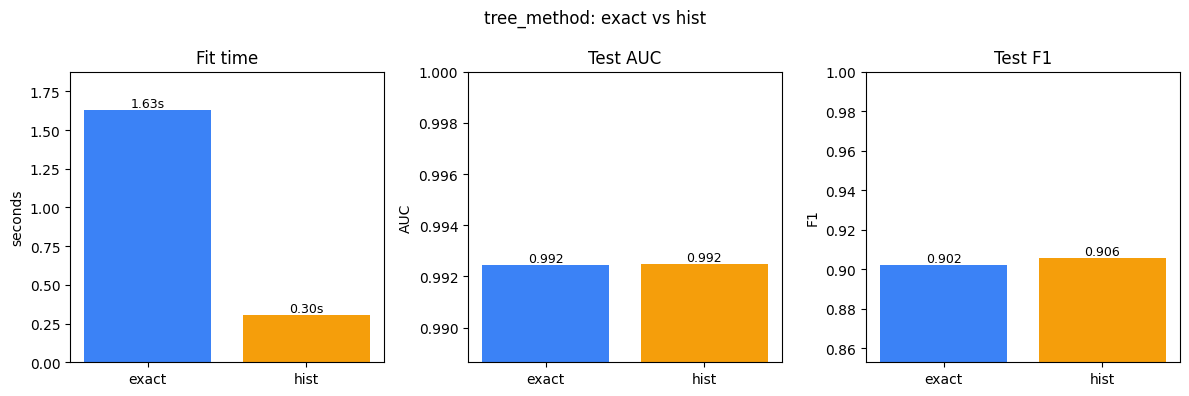

POST-PRUNING DIAGNOSTIC: post_prune=True (pruned) vs. False (unpruned)
  [early stopping] round 215: no improvement in 20 rounds — reverting to best iteration 195/300 (logloss=0.0885)
variant                       trees  total leaves  leaves/tree  train AUC  test AUC     gap
post_prune=True (pruned)        158          2524         16.0     0.9999    0.9926 +0.0073
post_prune=False (unpruned)     195          2287         11.7     0.9998    0.9925 +0.0073
A larger train-test AUC gap indicates more overfitting; more leaves for similar test AUC is wasted complexity.


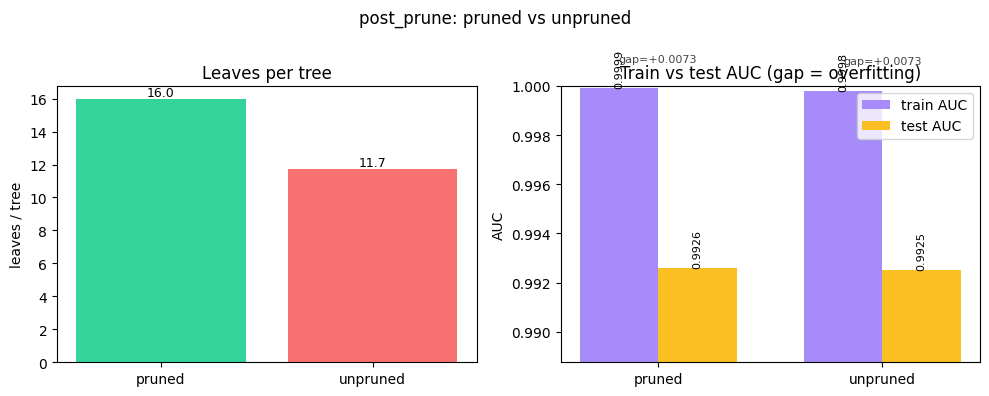

In [ ]:
print("SPLIT-FINDING DIAGNOSTIC: exact greedy best root split (round-0 gradients)")
g0, h0 = models["with_spw"].first_round_grad_, models["with_spw"].first_round_hess_
best_split_diag = ExactGreedySplitFinder(1.0, 0.0, 0.0, 1.0).best_split_all_features(X_train, g0, h0)
if best_split_diag is not None:
    print(f"Best split overall: feature='{feat_names[best_split_diag['feature']]}' "
          f"threshold={best_split_diag['threshold']:.4f}  gain={best_split_diag['gain']:.4f}  "
          f"default_direction={'left' if best_split_diag['default_left'] else 'right'}")

if XGBOOST_AVAILABLE:
    print("TREE-METHOD DIAGNOSTIC: xgboost tree_method='exact' vs. 'hist'")
    tm_rows = []
    for method in ("exact", "hist"):
        mtm = xgb.XGBClassifier(**{k: BASE_PARAMS[k] for k in
            ("n_estimators", "max_depth", "learning_rate", "reg_lambda", "reg_alpha", "gamma",
             "min_child_weight", "subsample", "colsample_bytree")},
            scale_pos_weight=spw_value, tree_method=method, eval_metric=EVAL_METRIC,
            early_stopping_rounds=ES_ROUNDS, random_state=0, n_jobs=-1)
        t0 = time.time()
        mtm.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
        fit_time_m = time.time() - t0
        vp = mtm.predict_proba(X_val)[:, 1]
        t_opt_m, _, _ = best_threshold(y_val, vp, metric="f1")
        tp = mtm.predict_proba(X_test)[:, 1]
        tm_rows.append((method, fit_time_m, auc_score(y_test, tp), f1_score(y_test, (tp >= t_opt_m).astype(int))))
    print(f"{'tree_method':<15}{'fit time (s)':>14}{'AUC':>10}{'F1':>10}")
    for method, fit_time_m, auc_m, f1_m in tm_rows:
        print(f"{method:<15}{fit_time_m:>14.2f}{auc_m:>10.4f}{f1_m:>10.4f}")
    print(f"'hist' is {tm_rows[0][1] / tm_rows[1][1]:.1f}x the speed of 'exact' here; at this data size "
          f"the accuracy difference is expected to be small since exact greedy has no quantization error.")

    tm_methods = [r[0] for r in tm_rows]
    tm_fit_times = [r[1] for r in tm_rows]
    tm_aucs = [r[2] for r in tm_rows]
    tm_f1s = [r[3] for r in tm_rows]
    colors_tm = ["#3b82f6", "#f59e0b"]

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    for ax, values, title, ylabel in (
        (axes[0], tm_fit_times, "Fit time", "seconds"),
        (axes[1], tm_aucs, "Test AUC", "AUC"),
        (axes[2], tm_f1s, "Test F1", "F1"),
    ):
        bars = ax.bar(tm_methods, values, color=colors_tm)
        ax.set_title(title); ax.set_ylabel(ylabel)
        lo = min(values)
        if title == "Fit time":
            ax.set_ylim(0, max(values) * 1.15)
        else:
            ax.set_ylim(max(0.0, lo - (1 - lo) * 0.5), 1.0)
        for b, v in zip(bars, values):
            ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.3f}" if title != "Fit time" else f"{v:.2f}s",
                     ha="center", va="bottom", fontsize=9)
    fig.suptitle("tree_method: exact vs hist")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "tree_method_exact_vs_hist.png"), dpi=150)
    plt.show()

print("POST-PRUNING DIAGNOSTIC: post_prune=True (pruned) vs. False (unpruned)")

unpruned = XGBoostFromScratchExact(**{**BASE_PARAMS, "scale_pos_weight": spw_value, "post_prune": False})
unpruned.fit(X_train, y_train, eval_set=(X_val, y_val), early_stopping_rounds=ES_ROUNDS)
print(f"{'variant':<28}{'trees':>7}{'total leaves':>14}{'leaves/tree':>13}{'train AUC':>11}{'test AUC':>10}{'gap':>8}")
for label, mm in (("post_prune=True (pruned)", models["with_spw"]), ("post_prune=False (unpruned)", unpruned)):
    total_leaves = sum(_count_leaves(t.root) for t in mm.trees)
    train_auc, test_auc = auc_score(y_train, mm.predict_proba(X_train)), auc_score(y_test, mm.predict_proba(X_test))
    print(f"{label:<28}{len(mm.trees):>7}{total_leaves:>14}{total_leaves / len(mm.trees):>13.1f}"
          f"{train_auc:>11.4f}{test_auc:>10.4f}{train_auc - test_auc:>+8.4f}")
print("A larger train-test AUC gap indicates more overfitting; more leaves for similar test AUC is wasted complexity.")

# Plot: pruned vs unpruned — leaves/tree, and train vs test AUC (with the gap
# annotated) side by side.
pp_labels, pp_trees, pp_leaves_per_tree, pp_train_auc, pp_test_auc = [], [], [], [], []
for label, mm in (("pruned", models["with_spw"]), ("unpruned", unpruned)):
    total_leaves = sum(_count_leaves(t.root) for t in mm.trees)
    pp_labels.append(label)
    pp_trees.append(len(mm.trees))
    pp_leaves_per_tree.append(total_leaves / len(mm.trees))
    pp_train_auc.append(auc_score(y_train, mm.predict_proba(X_train)))
    pp_test_auc.append(auc_score(y_test, mm.predict_proba(X_test)))
colors_pp = ["#34d399", "#f87171"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

bars = axes[0].bar(pp_labels, pp_leaves_per_tree, color=colors_pp)
axes[0].set_title("Leaves per tree"); axes[0].set_ylabel("leaves / tree")
for b, v in zip(bars, pp_leaves_per_tree):
    axes[0].text(b.get_x() + b.get_width() / 2, v, f"{v:.1f}", ha="center", va="bottom", fontsize=9)

x = np.arange(len(pp_labels))
width = 0.35
b1 = axes[1].bar(x - width / 2, pp_train_auc, width, label="train AUC", color="#a78bfa")
b2 = axes[1].bar(x + width / 2, pp_test_auc, width, label="test AUC", color="#fbbf24")
axes[1].set_xticks(x); axes[1].set_xticklabels(pp_labels)
axes[1].set_title("Train vs test AUC (gap = overfitting)"); axes[1].set_ylabel("AUC")
lo = min(pp_train_auc + pp_test_auc)
axes[1].set_ylim(max(0.0, lo - (1 - lo) * 0.5), 1.0)
for bars_, vals in ((b1, pp_train_auc), (b2, pp_test_auc)):
    for b, v in zip(bars_, vals):
        axes[1].text(b.get_x() + b.get_width() / 2, v, f"{v:.4f}", ha="center", va="bottom", fontsize=8, rotation=90)
for i in range(len(pp_labels)):
    gap = pp_train_auc[i] - pp_test_auc[i]
    axes[1].text(x[i], max(pp_train_auc[i], pp_test_auc[i]) + 0.001, f"gap={gap:+.4f}",
                  ha="center", va="bottom", fontsize=8, color="#444")
axes[1].legend()

fig.suptitle("post_prune: pruned vs unpruned")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "post_prune_pruned_vs_unpruned.png"), dpi=150)
plt.show()

GAMMA DIAGNOSTIC: tree shape across gamma=0, 1 (base), 2
  [early stopping] round 217: no improvement in 20 rounds — reverting to best iteration 197/300 (logloss=0.0835)
  [early stopping] round 268: no improvement in 20 rounds — reverting to best iteration 248/300 (logloss=0.0873)
gamma       trees  total leaves  leaves/tree  train AUC  test AUC     gap
0.0           197          5001         25.4     1.0000    0.9926 +0.0074
1.0           158          2524         16.0     0.9999    0.9926 +0.0073
2.0           248          2170          8.8     0.9997    0.9922 +0.0076
  [early stopping] round 226: no improvement in 20 rounds — reverting to best iteration 206/300 (logloss=0.0826)

gamma=0.0, post_prune=True : 25.4 leaves/tree
gamma=0.0, post_prune=False: 25.3 leaves/tree
-> No difference here — every split gamma=0 allowed already had positive gain on this data/split.


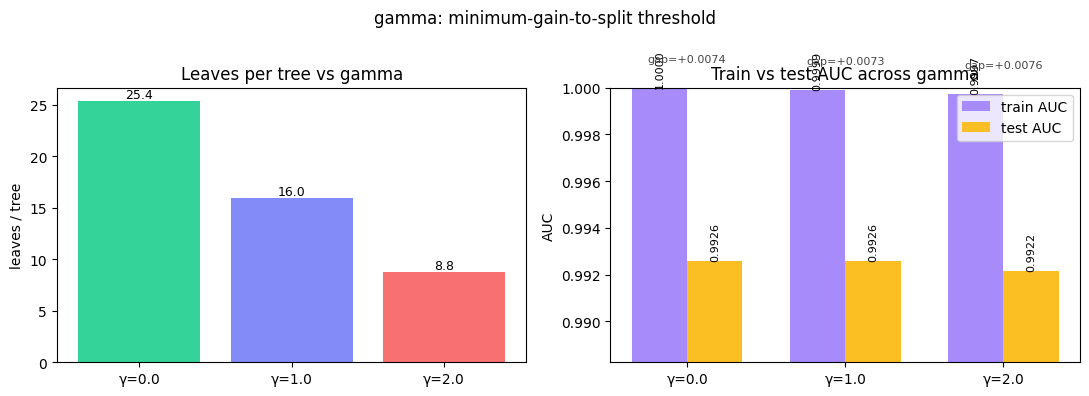

Saved /content/outputs/gamma_comparison.png


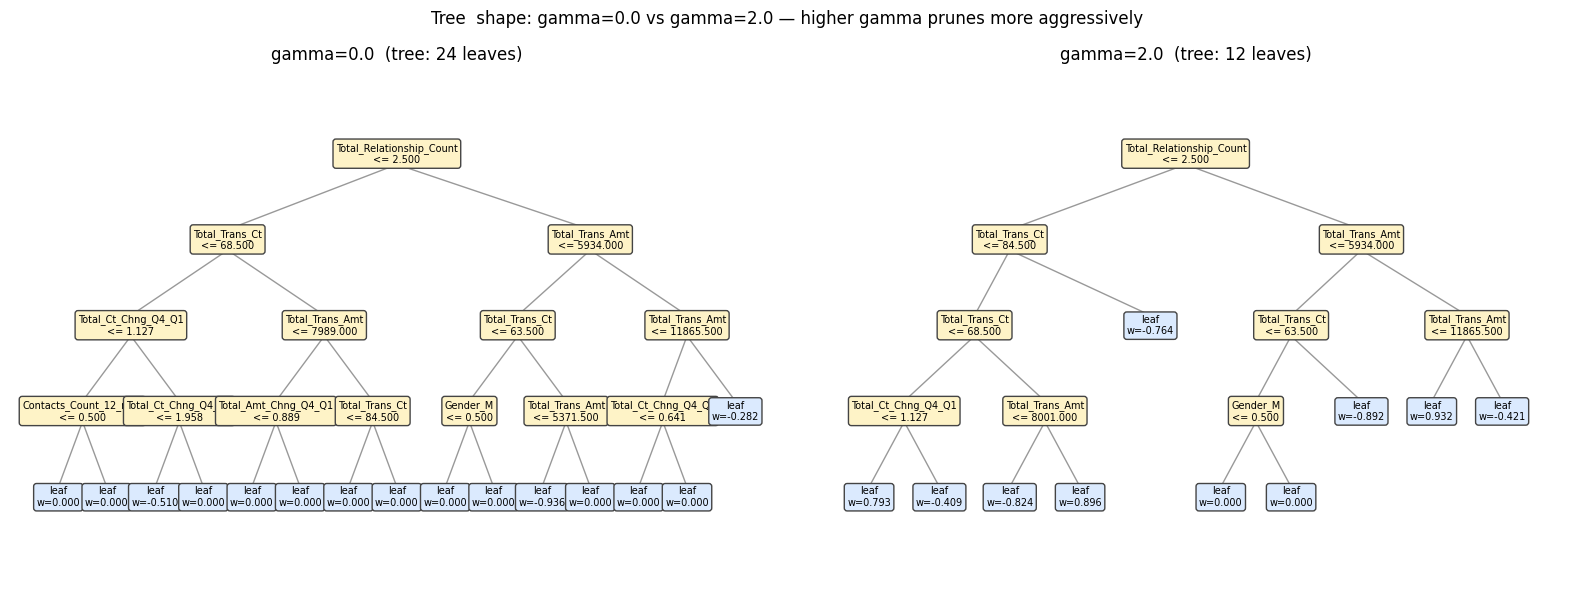

Saved /content/outputs/gamma_tree_comparison.png


In [ ]:

print("GAMMA DIAGNOSTIC: tree shape across gamma=0, 1 (base), 2")

gamma_values = [0.0, BASE_PARAMS["gamma"], 2.0]
gamma_models = {}

for gv in gamma_values:
    if gv == BASE_PARAMS["gamma"]:
        gamma_models[gv] = models["with_spw"]
        continue
    gparams = {**BASE_PARAMS, "scale_pos_weight": spw_value, "gamma": gv}
    gm = XGBoostFromScratchExact(**gparams)
    gm.fit(X_train, y_train, eval_set=(X_val, y_val), early_stopping_rounds=ES_ROUNDS)
    gamma_models[gv] = gm

print(f"{'gamma':<10}{'trees':>7}{'total leaves':>14}{'leaves/tree':>13}{'train AUC':>11}{'test AUC':>10}{'gap':>8}")
gamma_leaves_per_tree, gamma_train_auc, gamma_test_auc = [], [], []
for gv in gamma_values:
    gm = gamma_models[gv]
    total_leaves = sum(_count_leaves(t.root) for t in gm.trees)
    lpt = total_leaves / len(gm.trees)
    train_auc = auc_score(y_train, gm.predict_proba(X_train))
    test_auc = auc_score(y_test, gm.predict_proba(X_test))
    gamma_leaves_per_tree.append(lpt)
    gamma_train_auc.append(train_auc)
    gamma_test_auc.append(test_auc)
    print(f"{gv:<10.1f}{len(gm.trees):>7}{total_leaves:>14}{lpt:>13.1f}"
          f"{train_auc:>11.4f}{test_auc:>10.4f}{train_auc - test_auc:>+8.4f}")

gamma0_unpruned = XGBoostFromScratchExact(
    **{**BASE_PARAMS, "scale_pos_weight": spw_value, "gamma": 0.0, "post_prune": False})
gamma0_unpruned.fit(X_train, y_train, eval_set=(X_val, y_val), early_stopping_rounds=ES_ROUNDS)

leaves_pruned_g0 = sum(_count_leaves(t.root) for t in gamma_models[0.0].trees)
leaves_unpruned_g0 = sum(_count_leaves(t.root) for t in gamma0_unpruned.trees)
lpt_pruned_g0 = leaves_pruned_g0 / len(gamma_models[0.0].trees)
lpt_unpruned_g0 = leaves_unpruned_g0 / len(gamma0_unpruned.trees)

print(f"\ngamma=0.0, post_prune=True : {lpt_pruned_g0:.1f} leaves/tree")
print(f"gamma=0.0, post_prune=False: {lpt_unpruned_g0:.1f} leaves/tree")
if lpt_pruned_g0 < lpt_unpruned_g0:
    print(f"-> Even with gamma=0 contributing NOTHING to the gain penalty, post-pruning still "
          f"removed splits (fewer leaves/tree when pruned). This confirms gain <= 0 can happen from "
          f"the reg_lambda/reg_alpha similarity terms alone, independent of gamma.")
else:
    print(f"-> No difference here — every split gamma=0 allowed already had positive gain on this data/split.")

# --- Plot: leaves/tree and train-vs-test AUC gap, across gamma values ---
colors_gamma = ["#34d399", "#818cf8", "#f87171"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

gamma_labels = [f"γ={gv:.1f}" for gv in gamma_values]
bars = axes[0].bar(gamma_labels, gamma_leaves_per_tree, color=colors_gamma)
axes[0].set_title("Leaves per tree vs gamma")
axes[0].set_ylabel("leaves / tree")
for b, v in zip(bars, gamma_leaves_per_tree):
    axes[0].text(b.get_x() + b.get_width() / 2, v, f"{v:.1f}", ha="center", va="bottom", fontsize=9)

x = np.arange(len(gamma_labels))
width = 0.35
b1 = axes[1].bar(x - width / 2, gamma_train_auc, width, label="train AUC", color="#a78bfa")
b2 = axes[1].bar(x + width / 2, gamma_test_auc, width, label="test AUC", color="#fbbf24")
axes[1].set_xticks(x)
axes[1].set_xticklabels(gamma_labels)
axes[1].set_title("Train vs test AUC across gamma")
axes[1].set_ylabel("AUC")
lo = min(gamma_train_auc + gamma_test_auc)
axes[1].set_ylim(max(0.0, lo - (1 - lo) * 0.5), 1.0)
for bars_, vals in ((b1, gamma_train_auc), (b2, gamma_test_auc)):
    for b, v in zip(bars_, vals):
        axes[1].text(b.get_x() + b.get_width() / 2, v, f"{v:.4f}", ha="center", va="bottom", fontsize=8, rotation=90)
for i in range(len(gamma_labels)):
    gap = gamma_train_auc[i] - gamma_test_auc[i]
    axes[1].text(x[i], max(gamma_train_auc[i], gamma_test_auc[i]) + 0.001, f"gap={gap:+.4f}",
                 ha="center", va="bottom", fontsize=8, color="#444")
axes[1].legend()

fig.suptitle("gamma: minimum-gain-to-split threshold")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "gamma_comparison.png"), dpi=150)
plt.show()
print(f"Saved {os.path.join(OUTPUT_DIR, 'gamma_comparison.png')}")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
later_idx = min(50, len(gamma_models[0.0].trees) - 1)
for ax, gv in zip(axes, [0.0, 2.0]):
    tree_to_draw = gamma_models[gv].trees[later_idx]
    ...
    positions, leaf_counter = {}, [0]

    def _assign(node, depth):
        if node.is_leaf or depth >= 4:
            xx = leaf_counter[0]; leaf_counter[0] += 1
            positions[id(node)] = (xx, depth); return xx, xx
        lx, _ = _assign(node.left, depth + 1)
        _, rx = _assign(node.right, depth + 1)
        xx = (lx + rx) / 2.0
        positions[id(node)] = (xx, depth); return lx, rx

    _assign(tree_to_draw.root, 0)
    max_x = max(xx for xx, _ in positions.values()) or 1
    max_d = max(d for _, d in positions.values()) or 1

    def _draw(node, depth):
        xx, yy = positions[id(node)][0], -depth
        leaf = node.is_leaf or depth >= 4
        label = f"leaf\nw={node.weight:.3f}" if leaf else f"{feat_names[node.feature]}\n<= {node.threshold:.3f}"
        ax.text(xx, yy, label, ha="center", va="center", fontsize=7,
                bbox=dict(boxstyle="round,pad=0.3", fc="#dbeafe" if leaf else "#fef3c7", ec="#444"))
        if not leaf:
            for child in (node.left, node.right):
                cx, cy = positions[id(child)]
                ax.plot([xx, cx], [yy - 0.12, -cy + 0.12], color="#999", linewidth=1, zorder=0)
                _draw(child, depth + 1)

    _draw(tree_to_draw.root, 0)
    ax.set_xlim(-1, max_x + 1)
    ax.set_ylim(-(max_d + 1), 1)
    ax.axis("off")
    leaves_this = _count_leaves(tree_to_draw.root)
    ax.set_title(f"gamma={gv:.1f}  (tree: {leaves_this} leaves)")

fig.suptitle("Tree  shape: gamma=0.0 vs gamma=2.0 — higher gamma prunes more aggressively")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "gamma_tree_comparison.png"), dpi=150)
plt.show()
print(f"Saved {os.path.join(OUTPUT_DIR, 'gamma_tree_comparison.png')}")

In [ ]:
xgb_metrics = {}
if XGBOOST_AVAILABLE:
    for tag, spw in CONFIGS:
        xm = xgb.XGBClassifier(**{k: BASE_PARAMS[k] for k in
            ("n_estimators", "max_depth", "learning_rate", "reg_lambda", "reg_alpha", "gamma",
             "min_child_weight", "subsample", "colsample_bytree")},
            scale_pos_weight=spw, tree_method="exact", eval_metric=EVAL_METRIC,
            early_stopping_rounds=ES_ROUNDS, random_state=0, n_jobs=-1)
        t0 = time.time()
        xm.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
        xgb_fit_time = time.time() - t0
        vp = xm.predict_proba(X_val)[:, 1]
        t_opt_x, _, _ = best_threshold(y_val, vp, metric="f1")
        tp = xm.predict_proba(X_test)[:, 1]
        xmetrics = print_classification_report(
            f"{tag}: real xgboost.XGBClassifier (fit={xgb_fit_time:.1f}s, threshold={t_opt_x:.2f})",
            y_test, (tp >= t_opt_x).astype(int), tp)
        print(f"\n[{tag}: scratch vs xgboost]")
        for k in ("accuracy", "auc", "f1", "precision", "recall"):
            print(f"  {k:9s}: scratch={metrics[tag][k]:.4f}  xgboost={xmetrics[k]:.4f}  "
                  f"diff={metrics[tag][k] - xmetrics[k]:+.4f}")
        metrics[tag].update(xgb_auc=xmetrics["auc"], xgb_f1=xmetrics["f1"], xgb_fit_time=xgb_fit_time)
        xgb_metrics[tag] = {**xmetrics, "test_prob": tp, "model": xm}
else:
    print("Real xgboost comparison skipped — xgboost not installed (`pip install xgboost`).")



--- with_spw: real xgboost.XGBClassifier (fit=2.7s, threshold=0.66) ---
  Accuracy : 0.9694   AUC: 0.9924
  Precision: 0.9284   Recall: 0.8770   F1: 0.9020
  Confusion matrix — TP:428  FP:33  TN:2518  FN:60

[with_spw: scratch vs xgboost]
  accuracy : scratch=0.9717  xgboost=0.9694  diff=+0.0023
  auc      : scratch=0.9926  xgboost=0.9924  diff=+0.0002
  f1       : scratch=0.9106  xgboost=0.9020  diff=+0.0086
  precision: scratch=0.9241  xgboost=0.9284  diff=-0.0044
  recall   : scratch=0.8975  xgboost=0.8770  diff=+0.0205


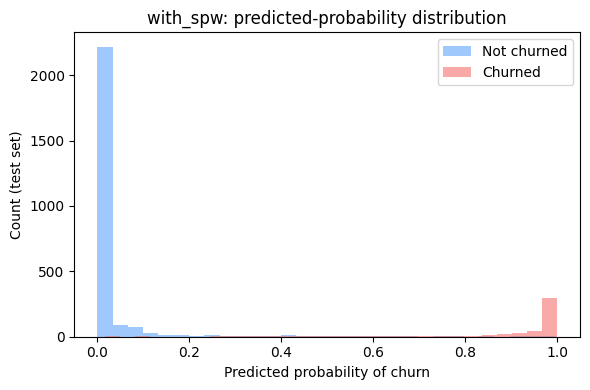

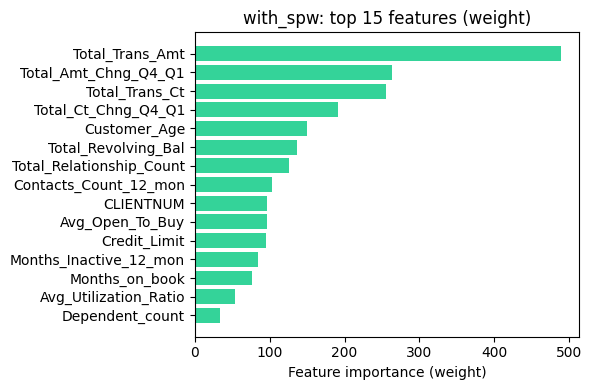

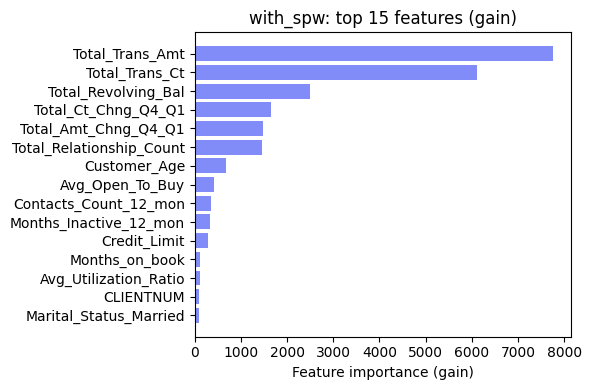

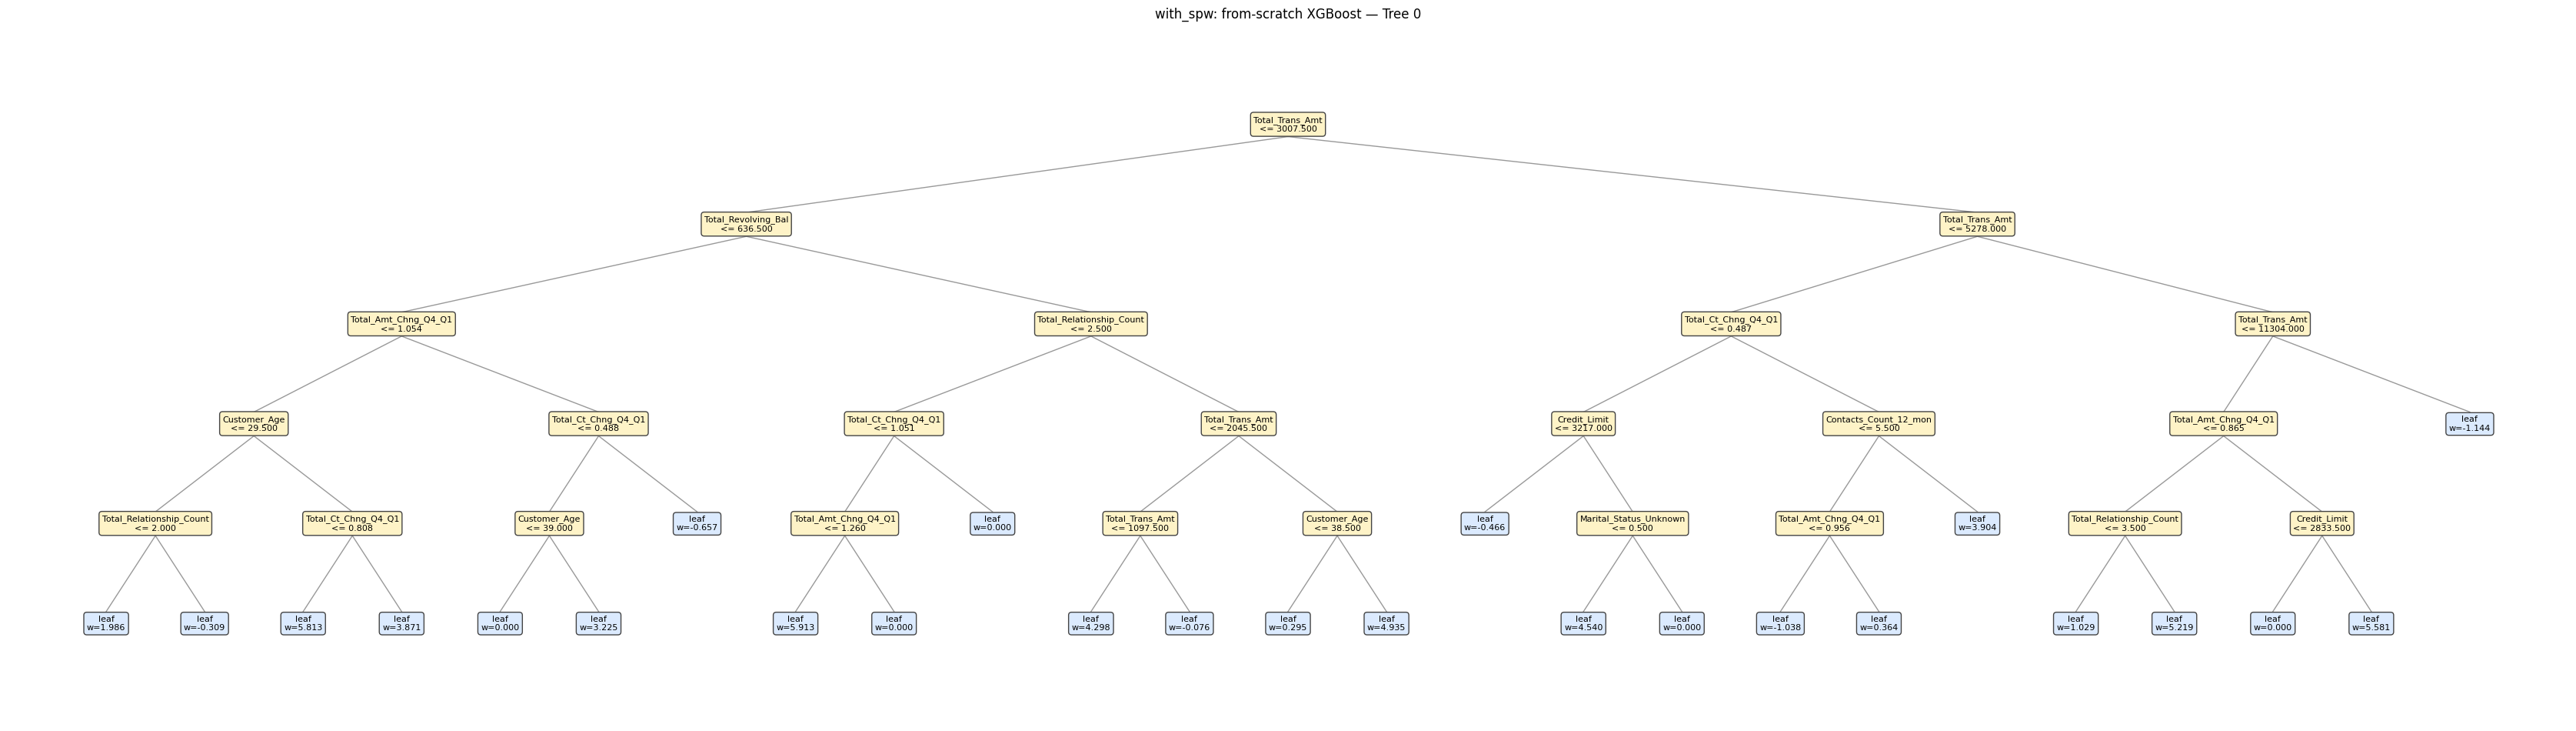

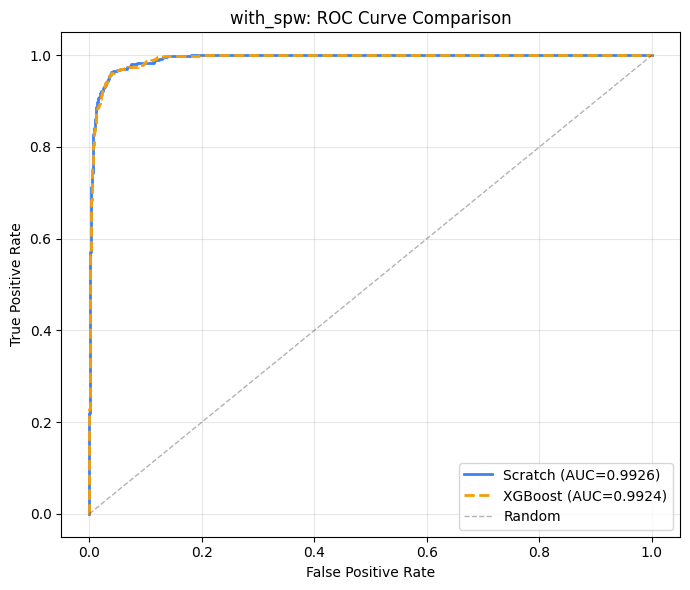

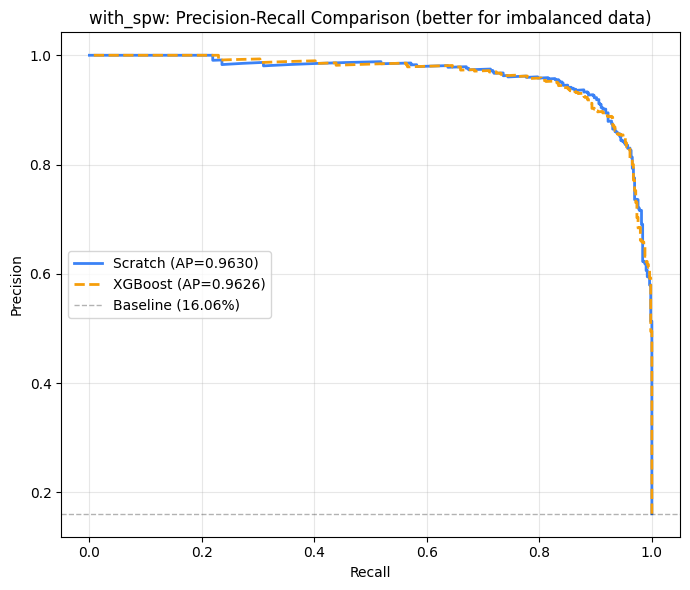


[with_spw] Top 10 feature importance (gain) — scratch vs xgboost:
Rank  Scratch                                 XGBoost                                 
1     Total_Trans_Amt                         Total_Trans_Ct                          
2     Total_Trans_Ct                          Total_Trans_Amt                         
3     Total_Revolving_Bal                     Total_Revolving_Bal                     
4     Total_Ct_Chng_Q4_Q1                     Total_Relationship_Count                
5     Total_Amt_Chng_Q4_Q1                    Total_Ct_Chng_Q4_Q1                     
6     Total_Relationship_Count                Avg_Utilization_Ratio                   
7     Customer_Age                            Total_Amt_Chng_Q4_Q1                    
8     Avg_Open_To_Buy                         Customer_Age                            
9     Contacts_Count_12_mon                   Months_Inactive_12_mon                  
10    Months_Inactive_12_mon                  Card_Category_Pla

In [ ]:
top_n, max_depth_to_draw = 15, 5
for tag, spw in CONFIGS:
    model, m = models[tag], metrics[tag]
    y_prob = m["test_prob"]

    plt.figure(figsize=(6, 4))
    plt.hist(y_prob[y_test == 0], bins=30, alpha=0.6, label="Not churned", color="#60a5fa")
    plt.hist(y_prob[y_test == 1], bins=30, alpha=0.6, label="Churned", color="#f87171")
    plt.xlabel("Predicted probability of churn"); plt.ylabel("Count (test set)")
    plt.title(f"{tag}: predicted-probability distribution"); plt.legend(); plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"{tag}_prob_hist.png"), dpi=150); plt.show()

    for imp, name, color in ((model.importance_, "weight", "#34d399"), (model.importance_gain_, "gain", "#818cf8")):
        order = np.argsort(imp)[::-1][:top_n]
        plt.figure(figsize=(6, 4))
        plt.barh([feat_names[i] for i in order][::-1], imp[order][::-1], color=color)
        plt.xlabel(f"Feature importance ({name})"); plt.title(f"{tag}: top {top_n} features ({name})")
        plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, f"{tag}_importance_{name}.png"), dpi=150); plt.show()

    tree0 = model.trees[0]
    positions, leaf_counter = {}, [0]

    def _assign(node, depth):
        if node.is_leaf or depth >= max_depth_to_draw:
            x = leaf_counter[0]; leaf_counter[0] += 1
            positions[id(node)] = (x, depth); return x, x
        lx, _ = _assign(node.left, depth + 1)
        _, rx = _assign(node.right, depth + 1)
        x = (lx + rx) / 2.0
        positions[id(node)] = (x, depth); return lx, rx

    _assign(tree0.root, 0)
    max_x = max(x for x, _ in positions.values()) or 1
    max_d = max(d for _, d in positions.values()) or 1
    fig, ax = plt.subplots(figsize=(max(8, max_x * 1.4), max(4, (max_d + 1) * 1.6)))

    def _draw(node, depth):
        x, y = positions[id(node)][0], -depth
        leaf = node.is_leaf or depth >= max_depth_to_draw
        label = f"leaf\nw={node.weight:.3f}" if leaf else f"{feat_names[node.feature]}\n<= {node.threshold:.3f}"
        ax.text(x, y, label, ha="center", va="center", fontsize=8,
                bbox=dict(boxstyle="round,pad=0.35", fc="#dbeafe" if leaf else "#fef3c7", ec="#444"))
        if not leaf:
            for child in (node.left, node.right):
                cx, cy = positions[id(child)]
                ax.plot([x, cx], [y - 0.12, -cy + 0.12], color="#999", linewidth=1, zorder=0)
                _draw(child, depth + 1)

    _draw(tree0.root, 0)
    ax.set_xlim(-1, max_x + 1); ax.set_ylim(-(max_d + 1), 1); ax.axis("off")
    ax.set_title(f"{tag}: from-scratch XGBoost — Tree 0")
    plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, f"{tag}_tree0.png"), dpi=150); plt.show()

    if XGBOOST_AVAILABLE:
        xp, xmodel = xgb_metrics[tag]["test_prob"], xgb_metrics[tag]["model"]
        fpr_s, tpr_s, _ = roc_curve(y_test, y_prob)
        fpr_x, tpr_x, _ = roc_curve(y_test, xp)
        plt.figure(figsize=(7, 6))
        plt.plot(fpr_s, tpr_s, label=f"Scratch (AUC={auc_score(y_test, y_prob):.4f})", linewidth=2, color="#3b82f6")
        plt.plot(fpr_x, tpr_x, label=f"XGBoost (AUC={auc_score(y_test, xp):.4f})", linewidth=2, color="#f59e0b", linestyle="--")
        plt.plot([0, 1], [0, 1], "k--", linewidth=1, alpha=0.3, label="Random")
        plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
        plt.title(f"{tag}: ROC Curve Comparison"); plt.legend(loc="lower right"); plt.grid(alpha=0.3)
        plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, f"{tag}_roc.png"), dpi=150); plt.show()

        prec_s, rec_s, _ = precision_recall_curve(y_test, y_prob)
        prec_x, rec_x, _ = precision_recall_curve(y_test, xp)
        baseline_pr = np.sum(y_test) / len(y_test)
        plt.figure(figsize=(7, 6))
        plt.plot(rec_s, prec_s, label=f"Scratch (AP={average_precision_score(y_test, y_prob):.4f})", linewidth=2, color="#3b82f6")
        plt.plot(rec_x, prec_x, label=f"XGBoost (AP={average_precision_score(y_test, xp):.4f})", linewidth=2, color="#f59e0b", linestyle="--")
        plt.axhline(baseline_pr, color="k", linestyle="--", linewidth=1, alpha=0.3, label=f"Baseline ({baseline_pr:.2%})")
        plt.xlabel("Recall"); plt.ylabel("Precision")
        plt.title(f"{tag}: Precision-Recall Comparison (better for imbalanced data)")
        plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
        plt.savefig(os.path.join(OUTPUT_DIR, f"{tag}_pr_curve.png"), dpi=150); plt.show()

        xgb_gain = xmodel.get_booster().get_score(importance_type="gain")
        xgb_gain_arr = np.array([xgb_gain.get(f"f{i}", 0.0) for i in range(len(feat_names))])
        top_cmp = 10
        top_scratch = [feat_names[i] for i in np.argsort(model.importance_gain_)[::-1][:top_cmp]]
        top_xgb = [feat_names[i] for i in np.argsort(xgb_gain_arr)[::-1][:top_cmp]]
        print(f"\n[{tag}] Top {top_cmp} feature importance (gain) — scratch vs xgboost:")
        print(f"{'Rank':<6}{'Scratch':<40}{'XGBoost':<40}")
        for rank in range(top_cmp):
            print(f"{rank + 1:<6}{top_scratch[rank]:<40}{top_xgb[rank]:<40}")
        overlap = len(set(top_scratch) & set(top_xgb))
        print(f"Feature overlap: {overlap}/{top_cmp} — "
              f"{'strong evidence of correct split-finding logic.' if overlap >= top_cmp * 0.7 else 'some differences in feature selection.'}")


In [ ]:
kf = KFold(n_splits=3, shuffle=True, random_state=123)
for tag, spw in CONFIGS:
    cv_params = {**CV_BASE_PARAMS, "scale_pos_weight": spw}
    fold_aucs, fold_f1s, fold_thresholds = [], [], []
    for fold, (tr_idx, va_idx) in enumerate(kf.split(X_A), 1):
        cv_model = XGBoostFromScratchExact(**cv_params)
        cv_model.fit(X_A[tr_idx], y[tr_idx])
        val_prob = cv_model.predict_proba(X_A[va_idx])
        fold_t, val_f1, _ = best_threshold(y[va_idx], val_prob, metric="f1")
        fold_aucs.append(auc_score(y[va_idx], val_prob)); fold_f1s.append(val_f1); fold_thresholds.append(fold_t)
        print(f"[{tag}] CV fold {fold}: train={len(tr_idx)}  val={len(va_idx)}  "
              f"AUC={fold_aucs[-1]:.4f}  best-threshold F1={val_f1:.4f}  threshold={fold_t:.2f}")

    cv_thr_mean, cv_thr_std = float(np.mean(fold_thresholds)), float(np.std(fold_thresholds))
    t_opt = metrics[tag]["threshold"]
    print(f"[{tag}] Mean CV AUC: {np.mean(fold_aucs):.4f}   Mean CV best-threshold F1: {np.mean(fold_f1s):.4f}")
    print(f"[{tag}] threshold stability: folds={[f'{t:.2f}' for t in fold_thresholds]} "
          f"(mean={cv_thr_mean:.2f}, std={cv_thr_std:.2f})  |  val-tuned threshold used above: {t_opt:.2f}")
    print(f"[{tag}]   " + ("[warn] val-tuned threshold differs from CV mean by more than 2 std devs — treat with caution."
          if abs(t_opt - cv_thr_mean) > max(2 * cv_thr_std, 0.05) else "val-tuned threshold is consistent with CV folds."))


[with_spw] CV fold 1: train=6751  val=3376  AUC=0.9943  best-threshold F1=0.9105  threshold=0.72
[with_spw] CV fold 2: train=6751  val=3376  AUC=0.9931  best-threshold F1=0.9141  threshold=0.61
[with_spw] CV fold 3: train=6752  val=3375  AUC=0.9931  best-threshold F1=0.9243  threshold=0.72
[with_spw] Mean CV AUC: 0.9935   Mean CV best-threshold F1: 0.9163
[with_spw] threshold stability: folds=['0.72', '0.61', '0.72'] (mean=0.69, std=0.05)  |  val-tuned threshold used above: 0.61
[with_spw]   val-tuned threshold is consistent with CV folds.


In [ ]:
tag, spw = CONFIGS[0]
m = metrics[tag]
print("SUMMARY (from-scratch XGBoostFromScratchExact, test set)")
print(f"scale_pos_weight = n_neg/n_pos = {spw:.4f} (upweights the minority churn class in the loss)")
print(f"\n{'threshold regime':<20}{'AUC':>8}{'F1':>10}{'Precision':>12}{'Recall':>10}")
tuned_label = f"tuned (thr={m['threshold']:.2f})"
print(f"{tuned_label:<20}{m['auc']:>8.4f}{m['f1']:>10.4f}{m['precision']:>12.4f}{m['recall']:>10.4f}")
print(f"{'fixed @ 0.50':<20}{'':>8}{m['fixed_f1']:>10.4f}{m['fixed_precision']:>12.4f}{m['fixed_recall']:>10.4f}")
print("\nThe tuned threshold is chosen on the validation set to maximize F1 — the realistic")
print("deployment setup. The fixed-0.50 row is a sanity check at the plain default threshold,")
print("independent of the threshold search.")

if XGBOOST_AVAILABLE:
    print("SUMMARY (real xgboost baseline, same splits/params)")
    print(f"{'':<20}{'scratch AUC':>13}{'xgb AUC':>10}{'scratch F1':>12}{'xgb F1':>9}")
    print(f"{tag:<20}{m['auc']:>13.4f}{m.get('xgb_auc', float('nan')):>10.4f}"
          f"{m['f1']:>12.4f}{m.get('xgb_f1', float('nan')):>9.4f}")

    scratch_time, xgb_time = m["fit_time"], m.get("xgb_fit_time", 1)
    print("TRAINING TIME: scratch vs official xgboost")
    print(f"Scratch: {scratch_time:.1f}s   XGBoost: {xgb_time:.1f}s   "
          f"({scratch_time / xgb_time:.1f}× faster) — official xgboost is optimized C++;")
    print("the scratch version prioritizes algorithmic clarity over speed.")

SUMMARY (from-scratch XGBoostFromScratchExact, test set)
scale_pos_weight = n_neg/n_pos = 5.2239 (upweights the minority churn class in the loss)

threshold regime         AUC        F1   Precision    Recall
tuned (thr=0.61)      0.9926    0.9106      0.9241    0.8975
fixed @ 0.50                    0.9060      0.8942    0.9180

The tuned threshold is chosen on the validation set to maximize F1 — the realistic
deployment setup. The fixed-0.50 row is a sanity check at the plain default threshold,
independent of the threshold search.
SUMMARY (real xgboost baseline, same splits/params)
                      scratch AUC   xgb AUC  scratch F1   xgb F1
with_spw                   0.9926    0.9924      0.9106   0.9020
TRAINING TIME: scratch vs official xgboost
Scratch: 24.5s   XGBoost: 2.7s   (9.2× faster) — official xgboost is optimized C++;
the scratch version prioritizes algorithmic clarity over speed.
